# NACC Freeze 74: Longitudinal Progression Analysis and Evaluation

**Private research notebook. Not a clinical diagnostic tool.**

This notebook presents the completed experiment and six exploratory comparisons. It reads aggregate outputs and figures generated from frozen checkpoints; it does not train models, resplit participants, optimize a threshold, or publish participant records.

All notebook outputs and artifacts are stored under the Git-ignored `artifacts/private_runs/` directory. Do not commit the executed notebook or share it without a disclosure review.

## 1. Problem Statement

Predict whether a participant with **Mild Cognitive Impairment (MCI) at an anchor visit develops Alzheimer dementia within the next 730 days**.

- Anchor cognitive status: `NACCUDSD = 3`.
- Positive outcome: the first dementia event after the anchor and within 730 days has `NACCUDSD = 4` and `NACCALZD = 1`.
- A preceding dementia diagnosis, or an earlier/tied non-AD or unknown-etiology dementia event, excludes the anchor.
- A negative requires no dementia event in the horizon and observed clinical follow-up through at least 730 days. This is a fixed-horizon complete-case task, not a survival model.
- Only information available by the anchor enters the predictors. Intermediate GRU scores target the same anchor outcome; they are not independently calibrated 24-month forecasts at each earlier visit.

**Important:** the primary test results were inspected before the comparison runs. All comparative test findings are exploratory. No clinical-validation claim is justified.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

search_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((path for path in search_roots if (path / 'pyproject.toml').exists() and (path / 'src/nacc_progression').exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Open this notebook from the project workspace.')
RUN_ROOT = PROJECT_ROOT / 'artifacts/private_runs/freeze74'
ASSETS = RUN_ROOT / 'analysis_assets'
if not (ASSETS / 'analysis_summary.json').is_file():
    raise RuntimeError('Missing frozen analysis assets. Generate them with nacc_progression.notebook_analysis.build_assets; this does not train.')
analysis = json.loads((ASSETS / 'analysis_summary.json').read_text())
primary = json.loads((RUN_ROOT / 'primary_multimodal/evaluation.json').read_text())
comparisons = json.loads((RUN_ROOT / 'exploratory_comparisons_2026-10-28/comparisons.json').read_text())
assert analysis['no_training_or_threshold_tuning'] is True
assert analysis['status'] == 'FROZEN_INFERENCE_ANALYSIS_COMPLETE'
counts = analysis['counts']

def show_figure(name):
    display(Image(filename=str(ASSETS / name)))

pd.set_option('display.max_columns', 20)
display(Markdown('**Source:** saved experiments and verified frozen-checkpoint inference. No training occurs in this notebook.'))

**Source:** saved experiments and verified frozen-checkpoint inference. No training occurs in this notebook.

## 2. Dataset and Cohort

**NACC Freeze 74**, using the UDS clinical columns in the delivered combined UDS/FTLD-LBD export and **Mixed-protocol quantitative MRI**, not CLARiTI, PET or raw MRI voxels. The CSV filename is not used to infer clinical diagnoses; the documented UDS columns determine eligibility.

The full source contains 57,038 clinical participants and 217,598 visits. Only **75 participants** satisfy the study criteria (55 non-progressions and 20 progressions), contributing 209 selected clinical visits. This is a highly selected, complete-follow-up convenience sample, not representative of all NACC participants.

The MRI source has 12,180 scan rows. There are 519 redundant rows identical in identity/date, availability and all requested measurements; these are collapsed in memory. Conflicting same-date measurements are rejected. No participant-level rows or identifiers are displayed.

,stage,participants
0,Clinical source,57038
1,At least one temporal MRI match,1611
2,Quantitative MRI matched,755
3,Eligible MCI anchor and follow-up,75


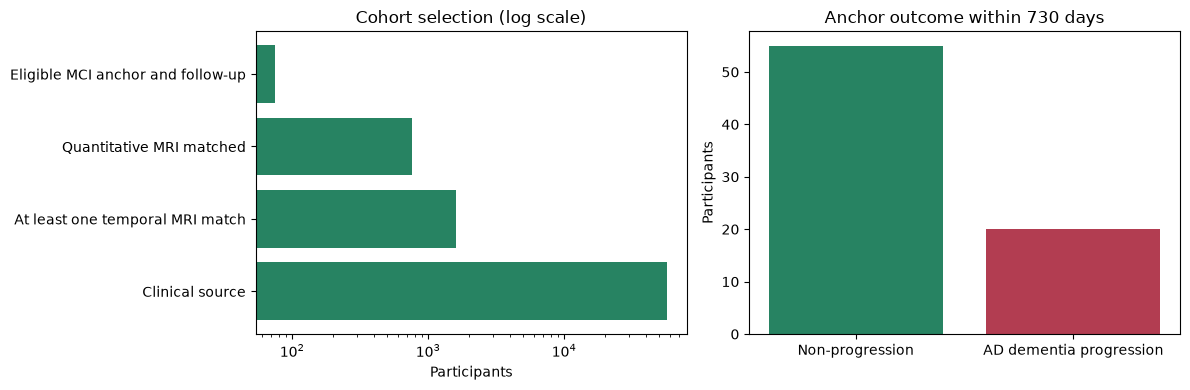

**Exclusion audit caution:** the saved exclusion categories overlap; they are not additive stages of the flow diagram.

In [2]:
cohort = counts['cohort_audit']
matching = counts['matching_audit']
stages = pd.DataFrame([
    {'stage': 'Clinical source', 'participants': cohort['clinical_timeline_participants']},
    {'stage': 'At least one temporal MRI match', 'participants': matching['matched_participants']},
    {'stage': 'Quantitative MRI matched', 'participants': cohort['participants_with_quantitative_mri']},
    {'stage': 'Eligible MCI anchor and follow-up', 'participants': cohort['eligible_participants']},
])
display(stages)
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(stages['stage'], stages['participants'], color='#278362')
axes[0].set_xscale('log')
axes[0].set(title='Cohort selection (log scale)', xlabel='Participants')
labels = ['Non-progression', 'AD dementia progression']
axes[1].bar(labels, [cohort['label_counts']['0'], cohort['label_counts']['1']], color=['#278362', '#b23d51'])
axes[1].set(title='Anchor outcome within 730 days', ylabel='Participants')
figure.tight_layout()
plt.show()
display(Markdown('**Exclusion audit caution:** the saved exclusion categories overlap; they are not additive stages of the flow diagram.'))

## 3. Methodology

1. Build identities from the canonical **site + participant** pair and use one private HMAC pseudonymization recipe across pipelines.
2. Normalize dates and match MRI acquired **on or before** a clinical visit within **0-90 days**. An eligible MCI visit takes priority over an intervening non-MCI visit; the closest qualifying scan is selected. No scan after the prediction anchor is allowed.
3. Keep the latest eligible MCI anchor per participant. Require **at least two distinct clinical visits, including the anchor**; pass at most the last three visits to the GRU. Historical visits may lack MRI, but the anchor must have a quantitative MRI (`NACCMVOL = 1`).
4. Use the complete clinical timeline only to establish future outcomes and follow-up. Future diagnoses, follow-up duration and time to dementia are not predictors.
5. Create **one stratified 70/15/15 patient split with seed 42**. The resulting counts are 52 train, 11 validation and 12 test. No search across splits was performed.
6. Convert each variable's documented NACC missing codes to missing values. Median-impute and z-score using training observations only. Sex is explicitly encoded, giving **six clinical values + six missing indicators** per visit.
7. Select MRI features with at most 20% missingness and nonzero observed variance **among available quantitative training MRI visits only (denominator: 69)**. Fit imputation/scaling on those visits only. **149/152** candidate features survive.
8. Represent entirely absent historical MRI by **zero after standardization + all-missing feature mask**. Do not fit MRI statistics on these placeholders. A partially missing observed MRI is a different situation: its missing values are median-imputed and masked.

The saved contract distinguishes missing measurements through masks, but it does not carry a separate modality-availability tensor. Placeholder attributions must not be read as observed anatomy.

In [3]:
split_rows = []
for split in ('train', 'validation', 'test'):
    item = counts['by_split'][split]
    outcomes = counts['split_label_counts'][split]
    split_rows.append({'split': split, 'participants': item['subjects'], 'non_progressions': outcomes['0'],
        'progressions': outcomes['1'], 'clinical_visits': item['visits'],
        'MRI_visits': item['quantitative_available_visits'],
        'visits_without_MRI': item['visits_without_quantitative_mri']})
display(pd.DataFrame(split_rows).set_index('split'))
display(pd.DataFrame([{
    'MRI_candidates': counts['candidate_mri_features'],
    'MRI_retained': counts['retained_mri_features'],
    'MRI_filter_train_denominator': counts['mri_missingness_denominator'],
    'redundant_MRI_rows_removed': counts['exact_duplicate_mri_rows_removed'],
    'future_MRI_matches': matching['future_mri_matches'],
}]))
display(Markdown('**Tensor contract:** clinical values `[batch, T, 6]`; MRI values `[batch, T, 149]`; corresponding missing masks; elapsed years `[batch, T, 1]`; contiguous-prefix padding mask. `T <= 3`. Packed sequences exclude padding from GRU states.'))

,participants,non_progressions,progressions,clinical_visits,MRI_visits,visits_without_MRI
split,,,,,,
train,52,38,14,145,69,76
validation,11,8,3,32,17,15
test,12,9,3,32,17,15


,MRI_candidates,MRI_retained,MRI_filter_train_denominator,redundant_MRI_rows_removed,future_MRI_matches
0,152,149,69,519,0


**Tensor contract:** clinical values `[batch, T, 6]`; MRI values `[batch, T, 149]`; corresponding missing masks; elapsed years `[batch, T, 1]`; contiguous-prefix padding mask. `T <= 3`. Packed sequences exclude padding from GRU states.

## 4. Architecture and Training Protocol

The model operates on **regional numerical MRI measurements**, not 3D image voxels.

```text
MRI values (149) + missing indicators (149)
  -> Linear(298,128) -> ReLU -> Dropout(0.20)
  -> Linear(128,64) -> ReLU

Clinical values (6) + missing indicators (6)
  -> Linear(12,32) -> ReLU -> Dropout(0.20)
  -> Linear(32,32) -> ReLU

MRI embedding (64) + clinical embedding (32) + elapsed years (1)
  -> Concatenated visit representation (97)
  -> Packed GRU(input=97, hidden=64, layers=1)
  -> Linear(64,32) -> ReLU -> Dropout(0.20) -> Linear(32,1)
  -> Sigmoid score for the anchor outcome
```

- Anchor-only `BCEWithLogitsLoss`; training `pos_weight = 38/14` computed from train labels.
- AdamW: learning rate 0.001, weight decay 0.0001, batch size 32, seed 42.
- Maximum 100 epochs; early stopping patience 10 on unweighted validation BCE.
- Primary training stopped after **12 epochs**, selecting **epoch 2**. With only 52 training sequences, each epoch has approximately two optimizer batches, explaining the short runtime.
- No pretrained imaging encoder, scheduler, hyperparameter sweep, probability recalibration, or alternative fusion was used.
- The recorded weighted training BCE and unweighted validation BCE are different objectives; their numerical levels are not directly comparable.

,MRI_features,clinical_features,MRI_embedding,clinical_embedding,GRU_hidden,dropout,max_epochs,epochs_run_primary,best_epoch_primary,patience,batch_size,pos_weight_train_only
0,149,6,64,32,64,0.2,100,12,2,10,32,2.714286


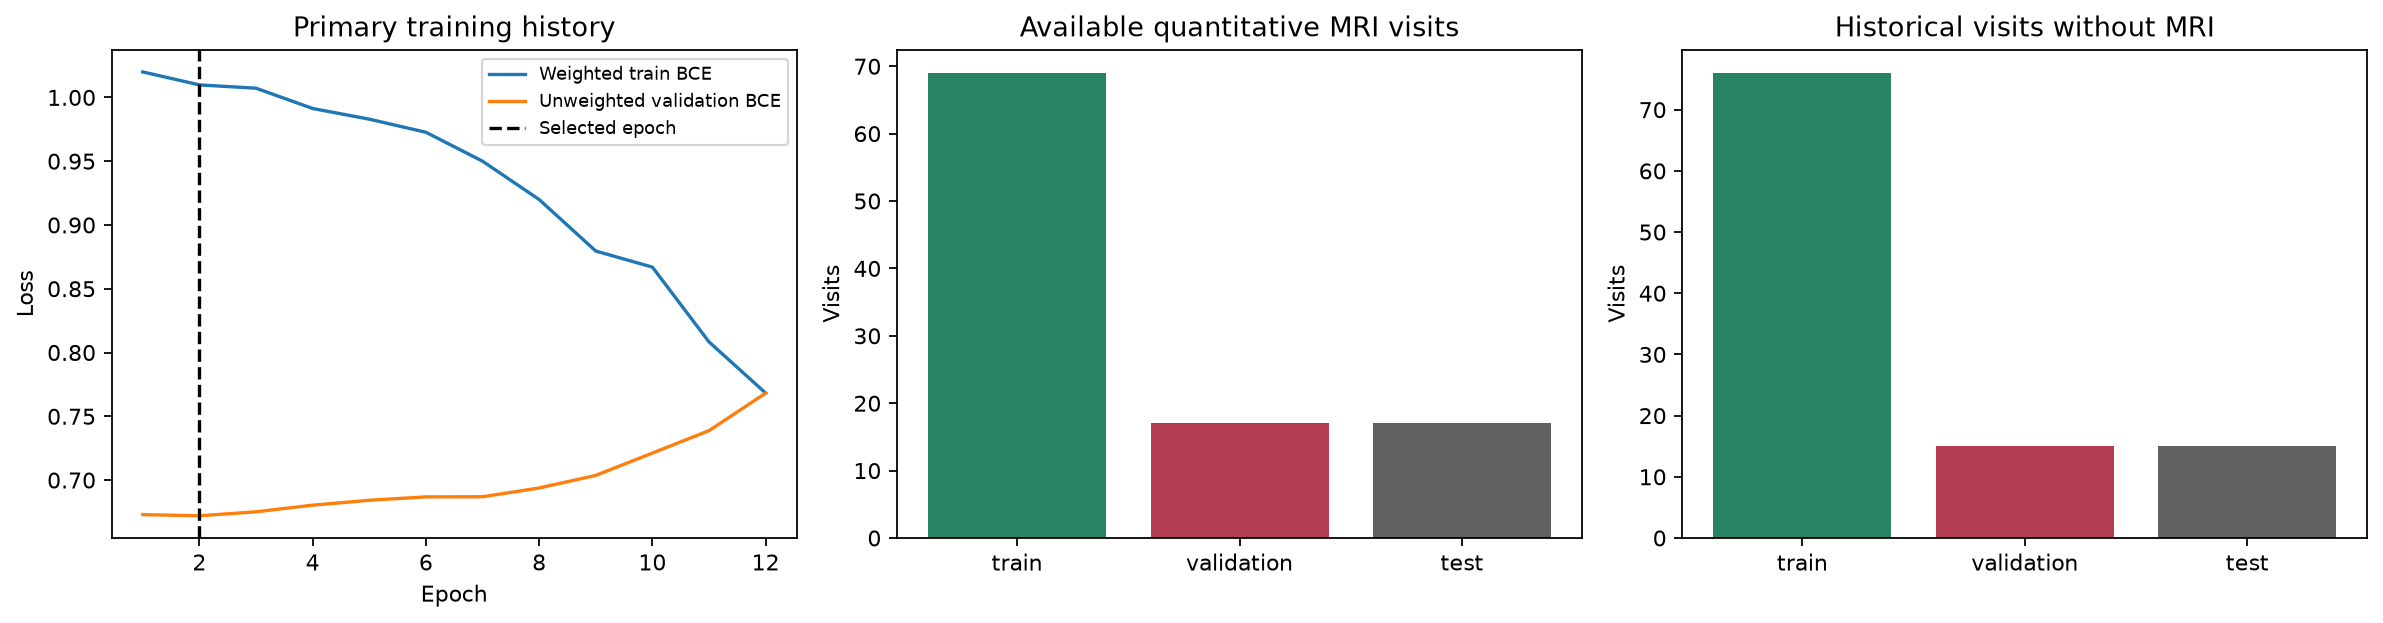

In [4]:
training = analysis['training_config']
architecture = analysis['model_config']
display(pd.DataFrame([{
    'MRI_features': architecture['imaging_features'],
    'clinical_features': architecture['clinical_features'],
    'MRI_embedding': architecture['imaging_embedding'],
    'clinical_embedding': architecture['clinical_embedding'],
    'GRU_hidden': architecture['temporal_hidden'],
    'dropout': architecture['dropout'],
    'max_epochs': training['max_epochs'],
    'epochs_run_primary': len(analysis['training_history']['training_losses']),
    'best_epoch_primary': analysis['training_history']['best_epoch'],
    'patience': training['patience'],
    'batch_size': training['batch_size'],
    'pos_weight_train_only': 38 / 14,
}]))
show_figure('learning_and_missingness.png')

## 5. Experiments

The **primary multimodal longitudinal GRU** was trained and evaluated first. Six comparison arms were subsequently executed on the **same cohort and patient split**, using the same preprocessing and feature order:

| Arm | Inputs | History |
|---|---|---|
| Logistic clinical | Clinical values + masks | Anchor visit only |
| Logistic MRI | MRI values + masks | Anchor visit only |
| Logistic multimodal | Both modalities + masks | Anchor visit only |
| Clinical GRU | Clinical + elapsed time | Up to 3 visits |
| MRI GRU | MRI + elapsed time | Up to 3 visits |
| Multimodal GRU | Both modalities + elapsed time | Up to 3 visits |

The primary run and the multimodal comparison row are repeated configurations, **not independent replications**. The comparison run reproduces the primary metrics. Unimodal GRUs remove the unused encoder; logistic baselines use class-balanced logistic regression.

Checkpoints/early stopping and decision thresholds are selected using validation only. Nevertheless, because the primary test results were viewed before running the comparisons, comparative test findings must remain exploratory. Do not select the largest test AUROC as a final winner.

**Design limitation:** logistic versus GRU changes both model family and history. These arms alone do not isolate the causal benefit of longitudinal modeling; a matched neural anchor-only baseline would be needed in a new prospectively defined experiment.

## 6. Results and Evaluation

All decision metrics below use the original **frozen validation-selected threshold**. No threshold was changed for this notebook.

- AUROC and AUPRC summarize ranking; AUPRC is average precision and should be compared with test prevalence (0.25).
- Sensitivity/recall, specificity, balanced accuracy, accuracy and F1 use the fixed threshold.
- PPV (precision) is undefined if there are no positive predictions; the notebook displays a missing value rather than claiming precision zero.
- NPV is the fraction of negative predictions that are true negatives.
- Brier score evaluates squared probability error. ECE and reliability plots are descriptive only; 12 test participants cannot establish calibration.
- Saved 95% bootstrap intervals resample participants, with one outcome per participant. Samples lacking both classes were omitted; these intervals are extremely unstable at this size and are not simultaneous intervals across models.

The primary multimodal GRU predicts all 12 test participants negative: **TN=9, FP=0, FN=3, TP=0**. Its accuracy of 0.75 merely matches the majority-class accuracy, while balanced accuracy is 0.50 and sensitivity is 0.00.

,threshold,best_epoch,auroc,auprc,accuracy,balanced_accuracy,sensitivity,specificity,f1,ppv,npv,brier_score,ece
model,,,,,,,,,,,,,
primary_multimodal,0.474,2.0,0.630,0.360,0.750,0.500,0.000,1.000,0.000,NaN,0.750,0.233,0.216
logistic_clinical_last_visit,0.454,NaN,0.852,0.810,0.667,0.667,0.667,0.667,0.500,0.400,0.857,0.164,0.261
logistic_imaging_last_visit,0.902,NaN,0.778,0.500,0.750,0.611,0.333,0.889,0.400,0.500,0.800,0.233,0.264
logistic_multimodal_last_visit,0.903,NaN,0.852,0.810,0.750,0.722,0.667,0.778,0.571,0.500,0.875,0.227,0.254
gru_clinical_longitudinal,0.442,29.0,0.926,0.867,0.667,0.778,1.000,0.556,0.600,0.429,1.000,0.158,0.216
gru_imaging_longitudinal,0.511,7.0,0.667,0.403,0.667,0.556,0.333,0.778,0.333,0.333,0.778,0.230,0.228
gru_multimodal_longitudinal,0.474,2.0,0.630,0.360,0.750,0.500,0.000,1.000,0.000,NaN,0.750,0.233,0.216


,auroc_95pct_CI,auprc_95pct_CI,balanced_accuracy_95pct_CI,brier_score_95pct_CI
model,,,,
primary_multimodal,"[0.300, 0.909]","[0.164, 0.833]","[0.500, 0.500]","[0.220, 0.250]"
logistic_clinical_last_visit,"[0.455, 1.000]","[0.200, 1.000]","[0.300, 0.950]","[0.073, 0.284]"
logistic_imaging_last_visit,"[0.455, 1.000]","[0.200, 1.000]","[0.350, 1.000]","[0.063, 0.427]"
logistic_multimodal_last_visit,"[0.455, 1.000]","[0.167, 1.000]","[0.364, 1.000]","[0.056, 0.441]"
gru_clinical_longitudinal,"[0.667, 1.000]","[0.333, 1.000]","[0.611, 0.944]","[0.068, 0.252]"
gru_imaging_longitudinal,"[0.300, 1.000]","[0.167, 1.000]","[0.278, 0.909]","[0.215, 0.247]"
gru_multimodal_longitudinal,"[0.286, 0.909]","[0.167, 0.821]","[0.500, 0.500]","[0.221, 0.250]"


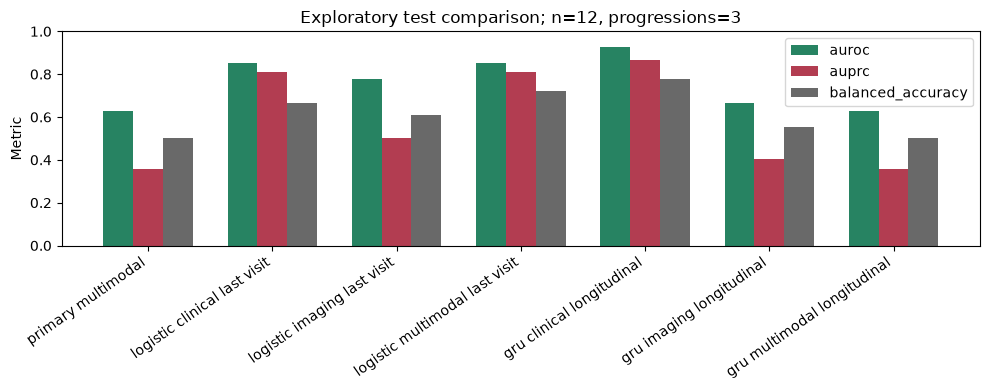

In [5]:
results = pd.DataFrame(analysis['comparison_rows']).set_index('model')
metric_columns = ['threshold', 'best_epoch', 'auroc', 'auprc', 'accuracy', 'balanced_accuracy',
                  'sensitivity', 'specificity', 'f1', 'ppv', 'npv', 'brier_score', 'ece']
display(results[metric_columns].round(3))
interval_rows = []
for model, intervals in analysis['confidence_intervals'].items():
    item = {'model': model}
    for metric, bounds in intervals.items():
        item[metric + '_95pct_CI'] = f'[{bounds[0]:.3f}, {bounds[1]:.3f}]' if None not in bounds else 'Not estimable'
    interval_rows.append(item)
display(pd.DataFrame(interval_rows).set_index('model'))
figure, axis = plt.subplots(figsize=(10, 4))
positions = np.arange(len(results))
for offset, metric, color in [(-.24, 'auroc', '#278362'), (0, 'auprc', '#b23d51'), (.24, 'balanced_accuracy', '#696969')]:
    axis.bar(positions + offset, results[metric], width=.24, label=metric, color=color)
axis.set_xticks(positions, [name.replace('_', ' ') for name in results.index], rotation=35, ha='right')
axis.set(ylim=(0, 1), ylabel='Metric', title='Exploratory test comparison; n=12, progressions=3')
axis.legend()
figure.tight_layout()
plt.show()

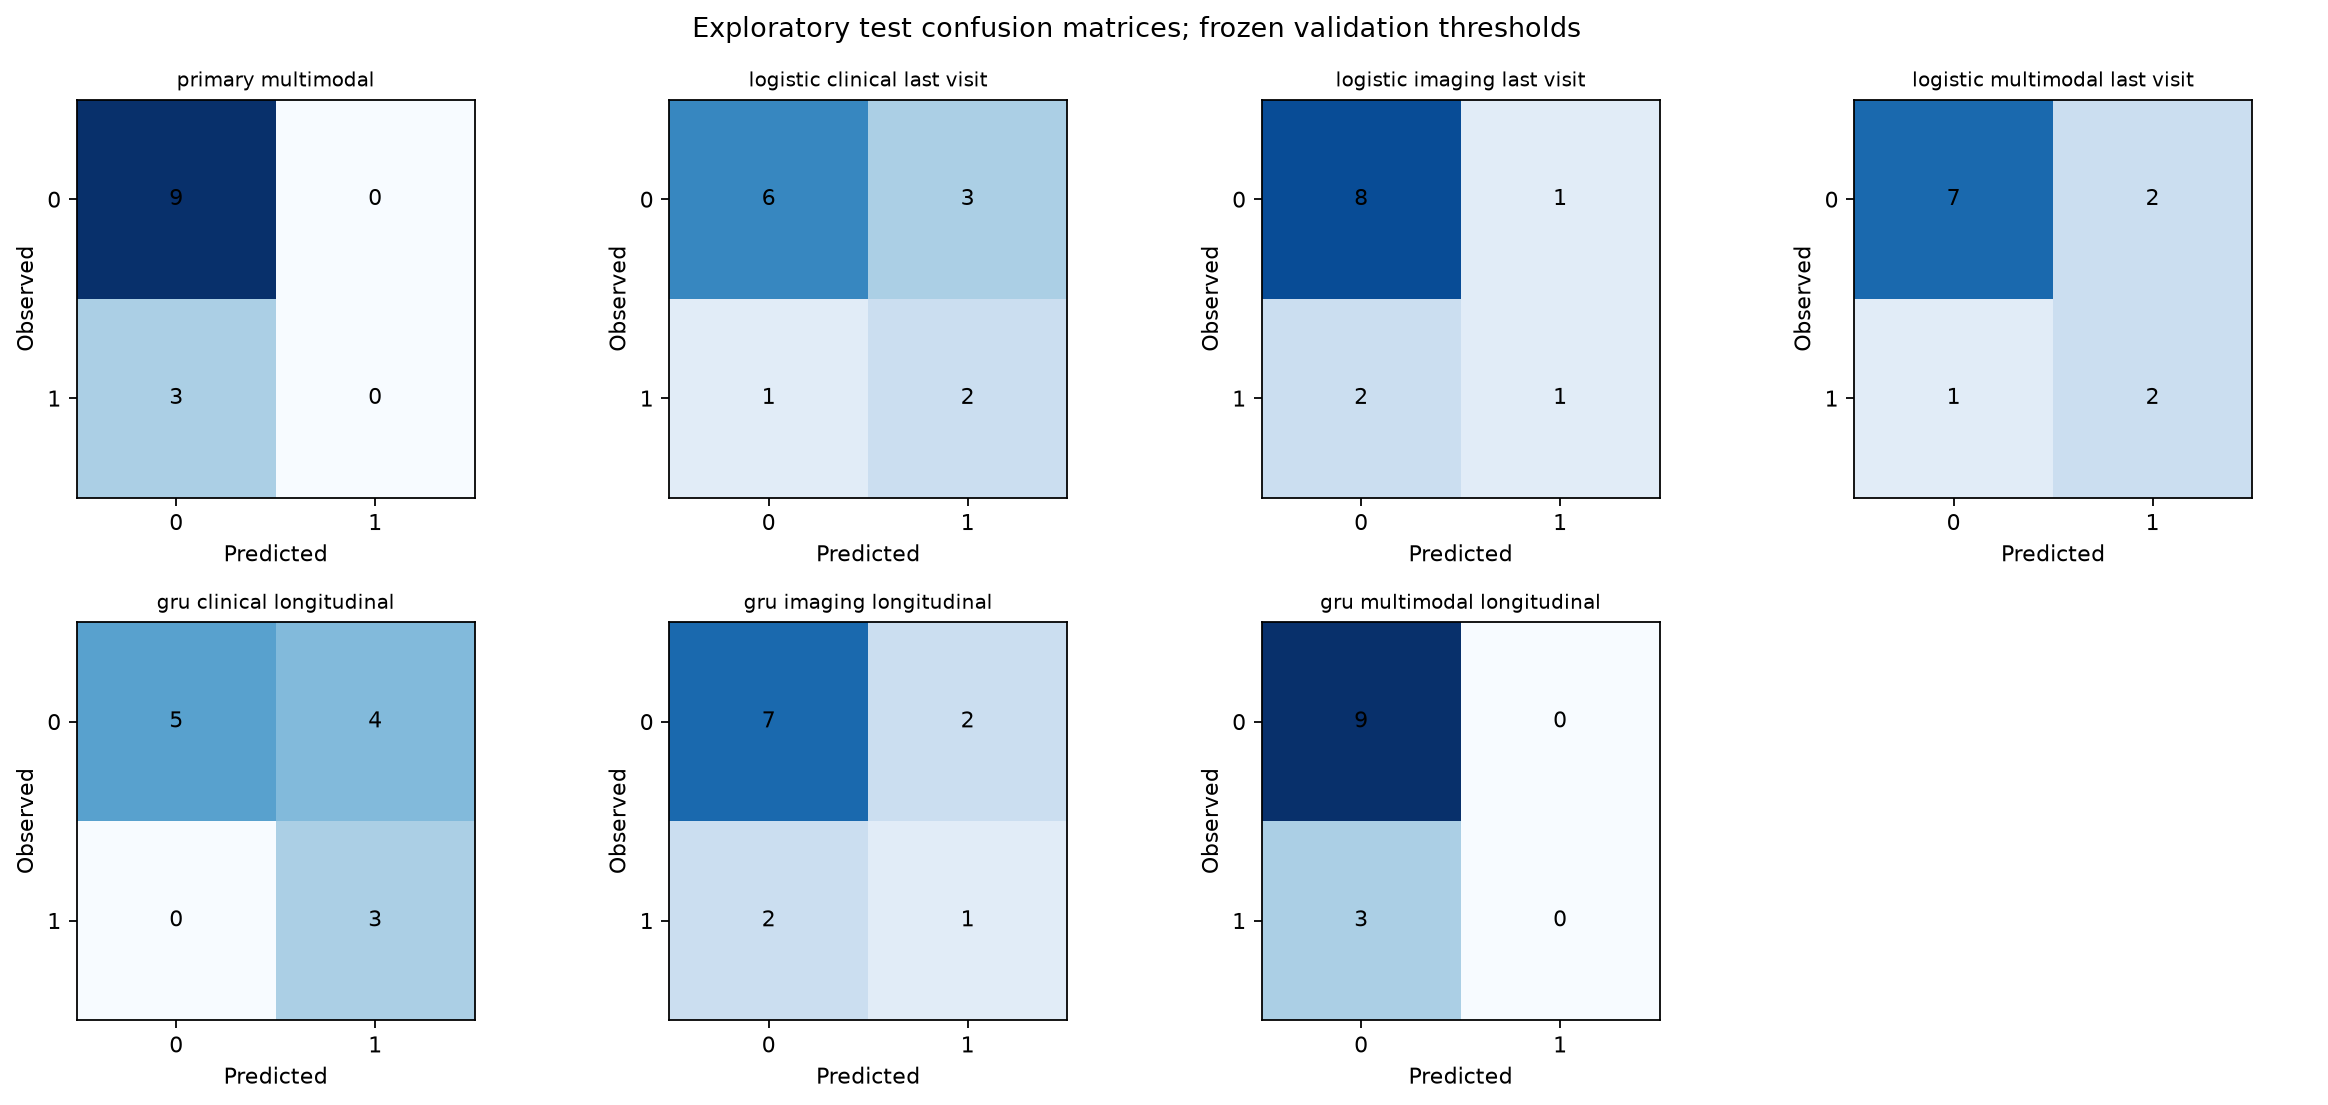

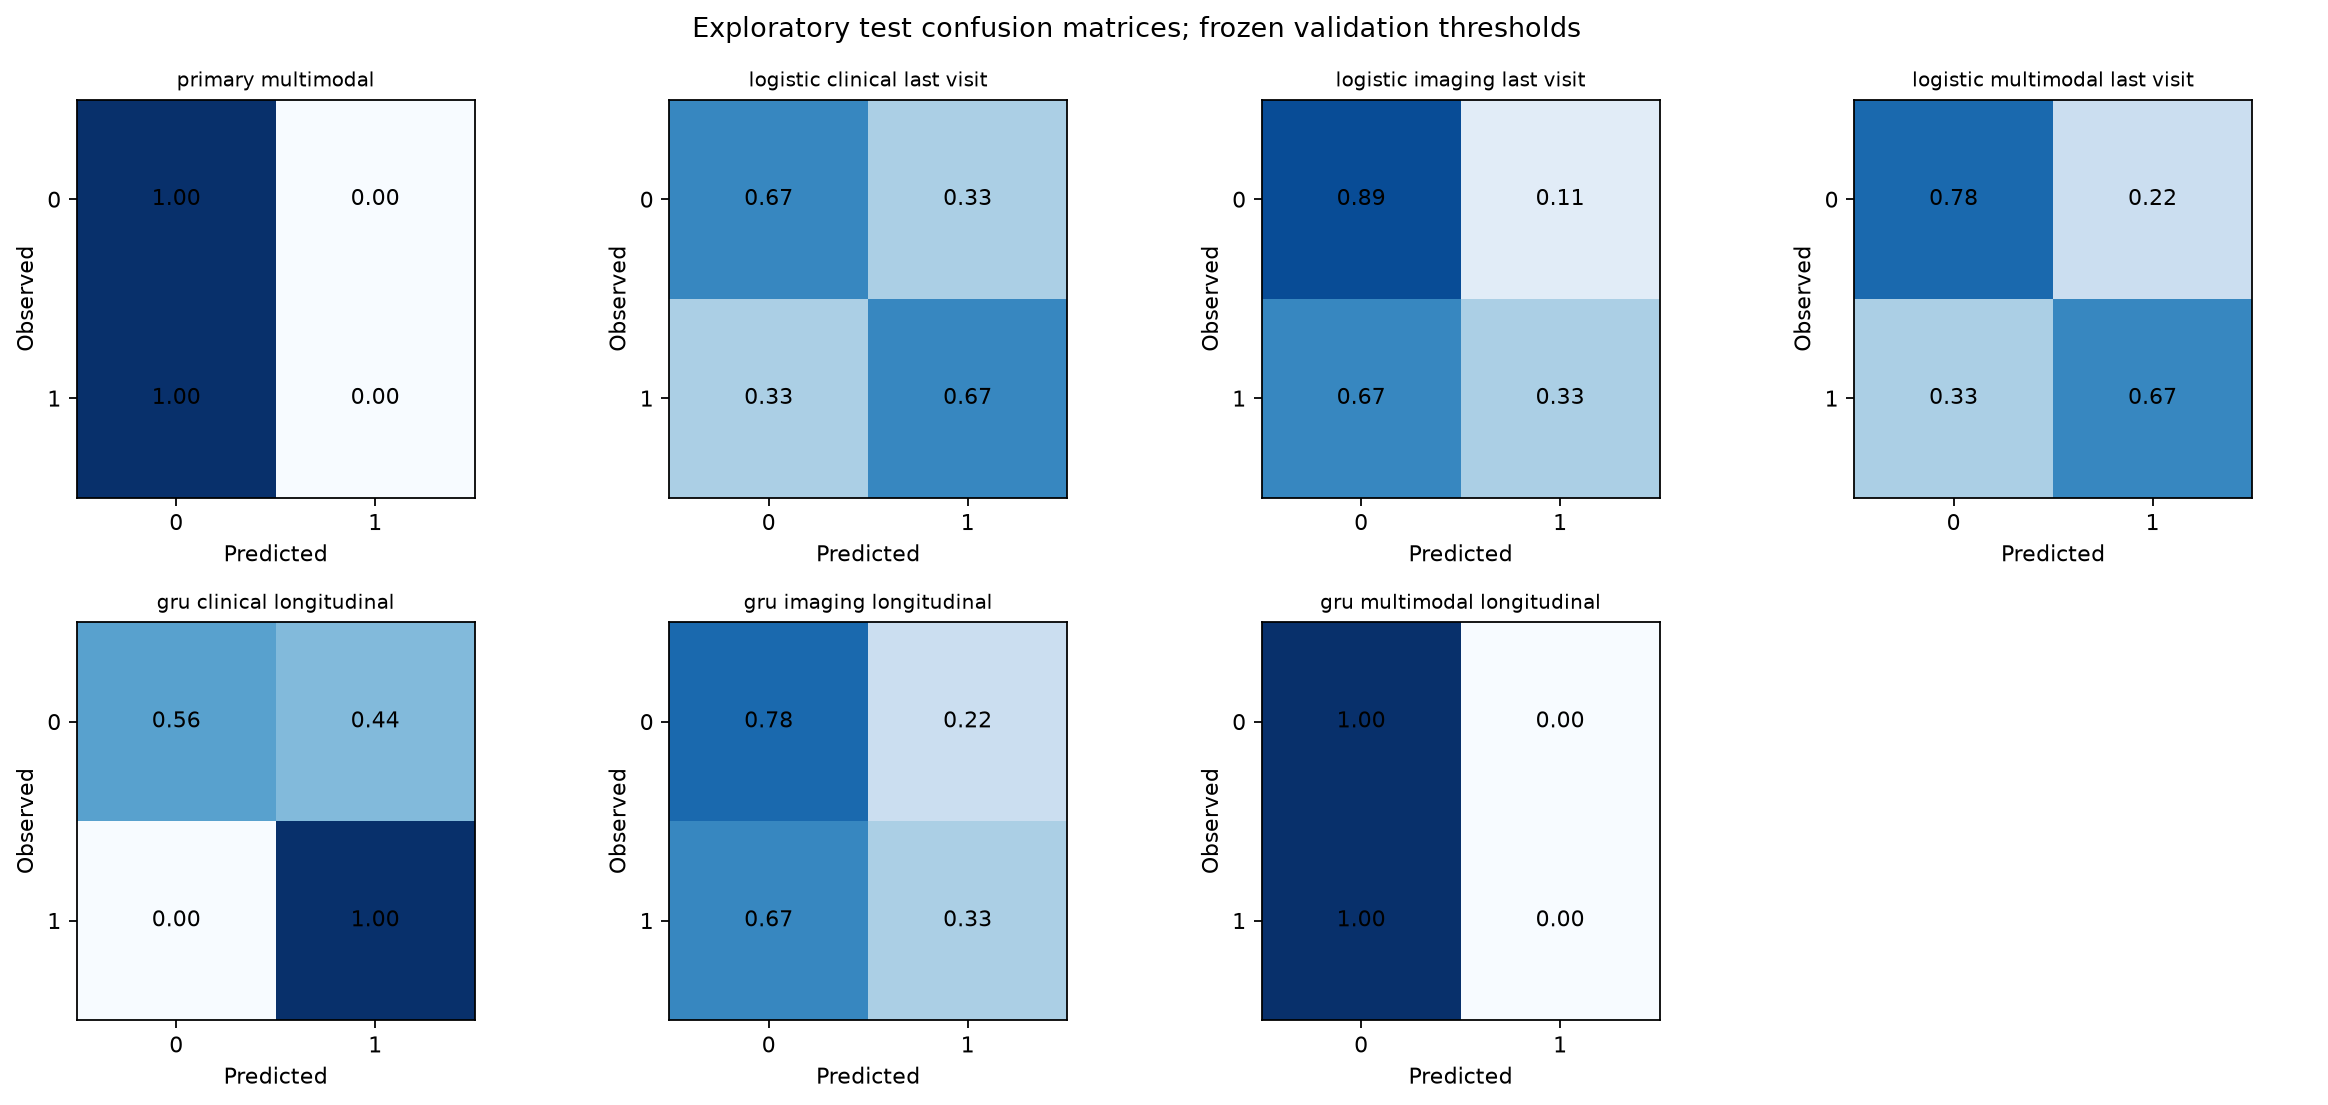

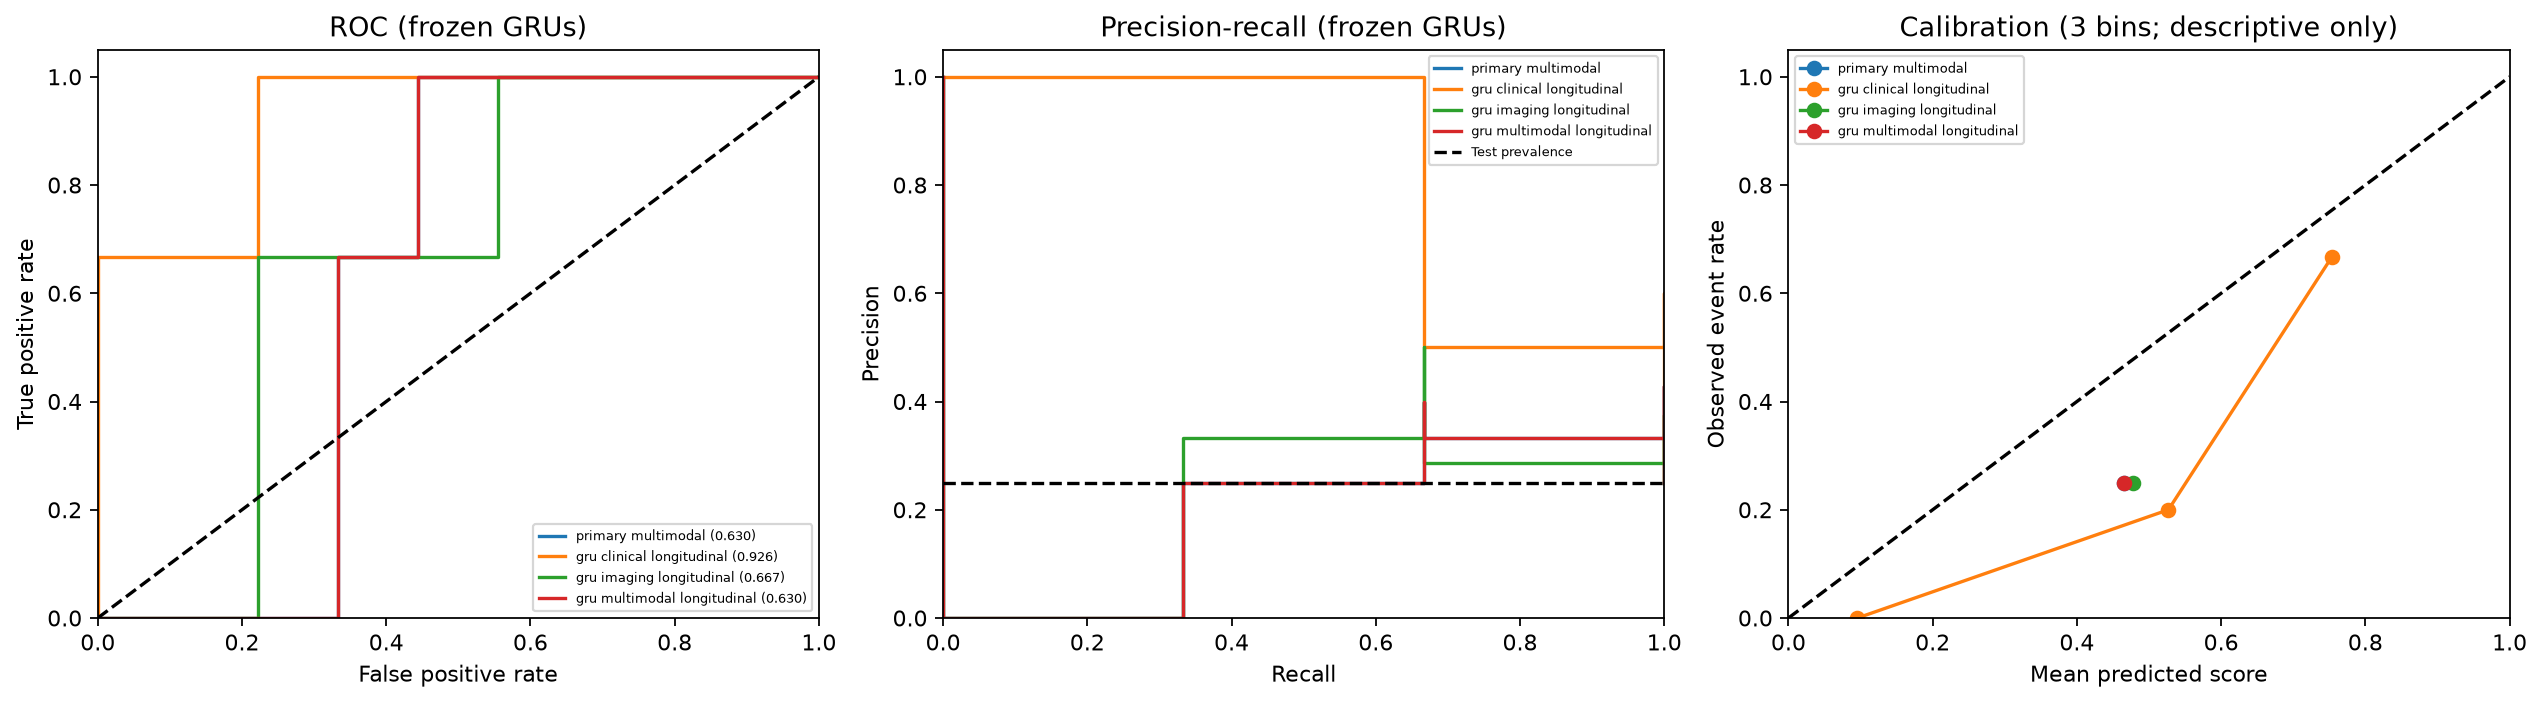

**Curve provenance:** ROC/PR/reliability curves use inference from the saved GRU checkpoints. Every recomputed test metric was checked against the saved experiment (tolerance 1e-7). Logistic estimators and scores were not saved, so their ROC/PR curves cannot be reconstructed without refitting; no refitting was done. Three calibration bins are used for visualization only; saved ECE uses ten bins.

,n,prevalence,auroc,auprc,balanced_accuracy,sensitivity,specificity,brier_score
train,52.0,0.269,0.957,0.911,0.857,0.714,1.000,0.232
validation,11.0,0.273,0.417,0.353,0.604,0.333,0.875,0.239


**Development snapshot:** these are final-checkpoint train/validation scores, not epoch-by-epoch AUROC curves. Validation was used for early stopping and threshold selection, so its scores are not an independent generalization estimate.

In [9]:
show_figure('confusion_counts.png')
show_figure('confusion_normalized.png')
show_figure('frozen_gru_curves.png')
display(Markdown('**Curve provenance:** ROC/PR/reliability curves use inference from the saved GRU checkpoints. Every recomputed test metric was checked against the saved experiment (tolerance 1e-7). Logistic estimators and scores were not saved, so their ROC/PR curves cannot be reconstructed without refitting; no refitting was done. Three calibration bins are used for visualization only; saved ECE uses ten bins.'))
development = pd.DataFrame(analysis['primary_development_metrics']).T
show_columns = ['n', 'prevalence', 'auroc', 'auprc', 'balanced_accuracy', 'sensitivity', 'specificity', 'brier_score']
display(development[show_columns].round(3))
display(Markdown('**Development snapshot:** these are final-checkpoint train/validation scores, not epoch-by-epoch AUROC curves. Validation was used for early stopping and threshold selection, so its scores are not an independent generalization estimate.'))

## 7. Explainability

**Integrated Gradients (IG)** is applied to the frozen primary model's **anchor logit**. The existing implementation uses a 64-point trapezoidal path integral; no new predictive model is fitted.

The reference is zero in normalized value space (the training mean), with MRI/clinical missingness indicators held fixed. IG describes value and elapsed-time contributions **conditional on that missingness pattern**; it does not explain the contribution of missingness flags themselves.

- Clinical variables: age, encoded sex, education, global CDR, CDR sum of boxes, MMSE.
- MRI features: numerical regional volume/thickness measurements identified by their NACC RDD codes, not pixels. For example, `LHIPPO`/`RHIPPO` are left/right hippocampal volumes, `HIPPOVOL` is bilateral hippocampal volume, `LENT`/`RENT` are entorhinal volumes, and `LENTM`/`RENTM` are entorhinal mean cortical thickness. Check units per variable in the MRI dictionary; volume and thickness attributions are not physical quantities.
- Global importance is mean absolute IG summed over available visits. This loses sign and reflects the model's sensitivity, not a clinically causal association.
- Temporal attributions below are aligned to the **anchor** (0), previous visit (-1), and second previous visit (-2). The number of contributing patients varies with history length.
- Entirely absent MRI visits use zero placeholders. Their MRI value IG is zero under this reference, but that does **not** mean MRI absence has no influence: the fixed missingness flags can still affect predictions.

The absolute completeness residual is checked in logit units. Completeness is a numerical consistency check, not proof of faithful or clinically valid explanations.

**Leave-one-visit-out** is an additional fixed-model diagnostic. Time gaps are bridged after visit removal. Removing the anchor does not define a new outcome horizon; it still probes the original anchor target and may create out-of-distribution histories.

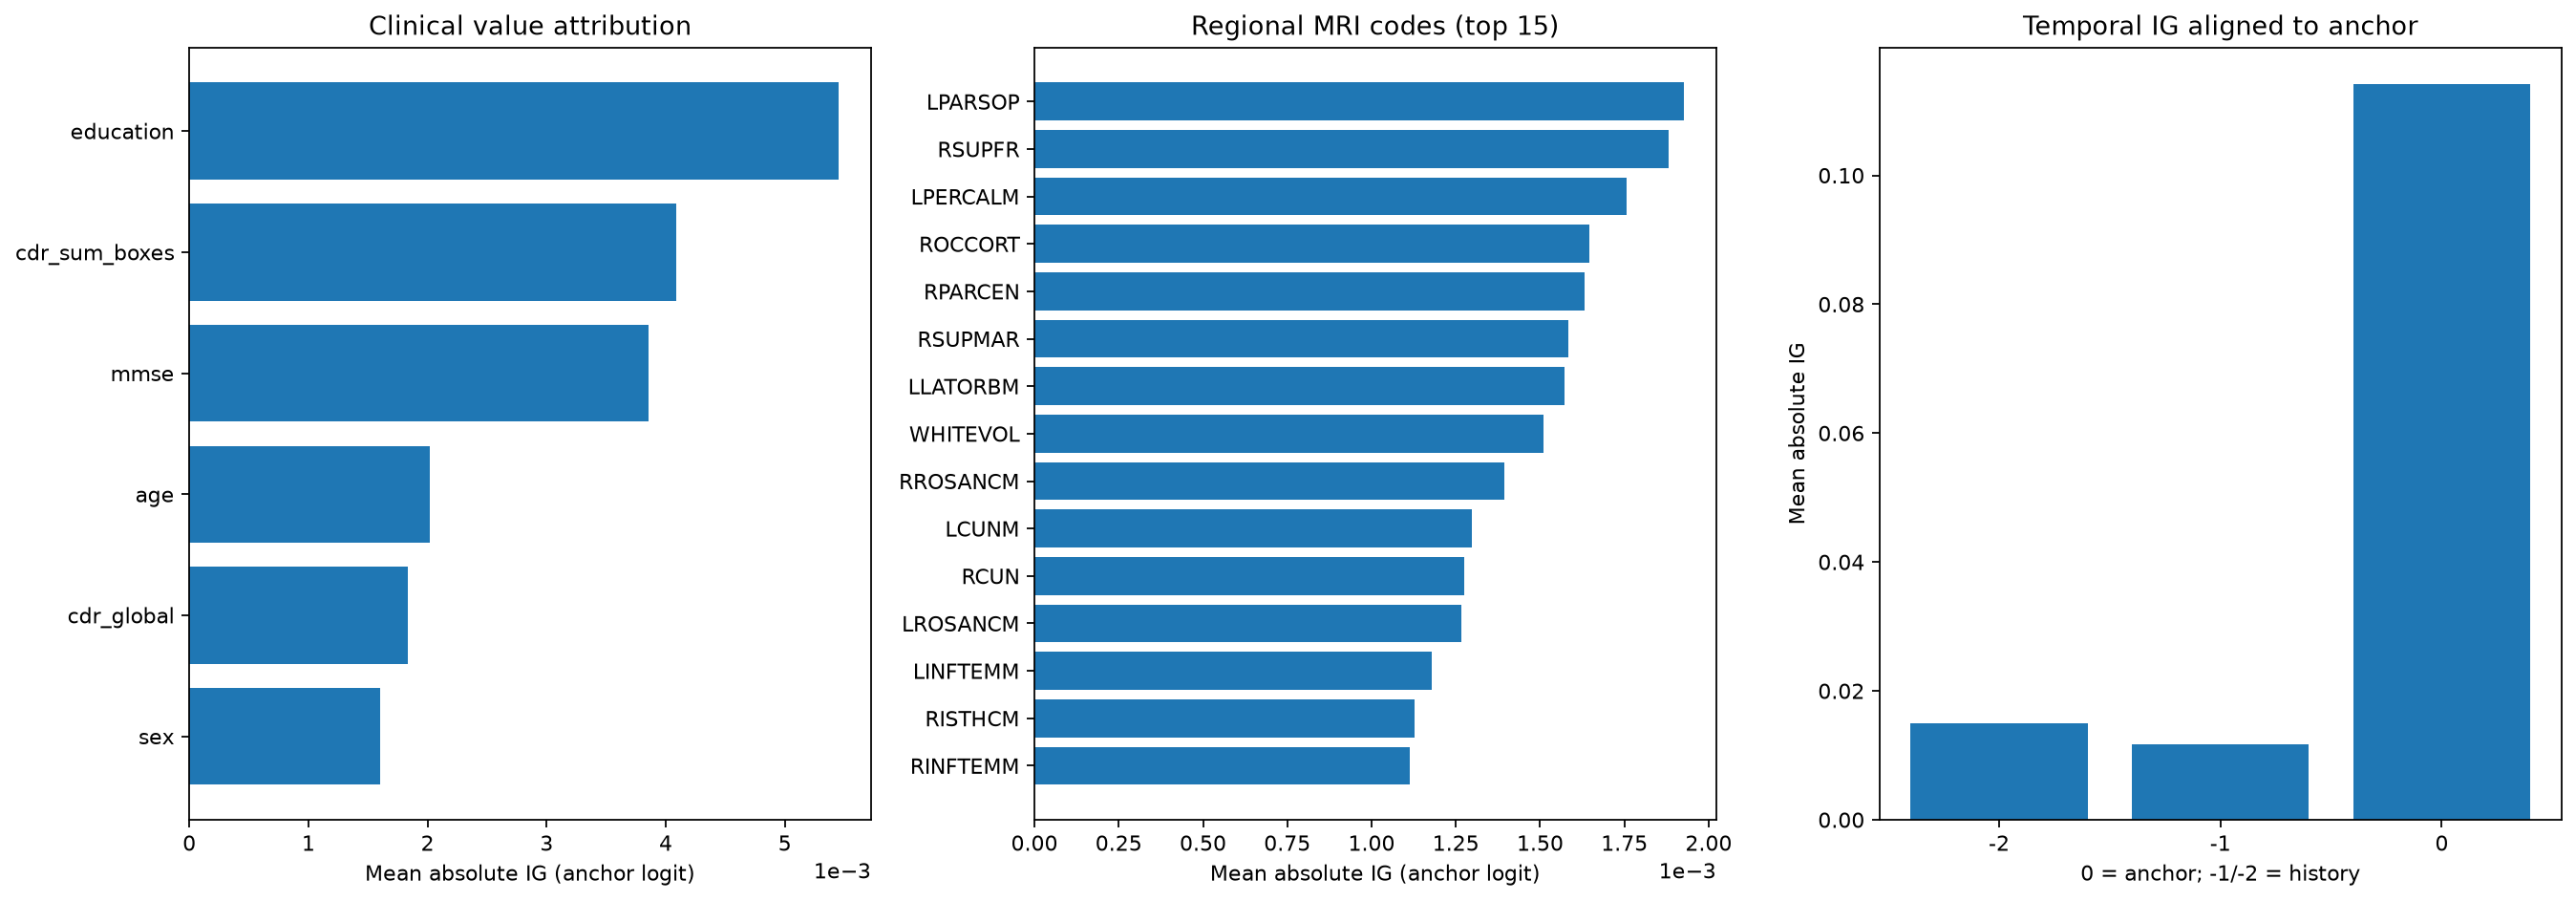

,visit_relative_to_anchor,patients,mean_abs_ig,mri_absent_fraction
0,-2,8,0.01502,0.50000
1,-1,12,0.01165,0.91667
2,0,12,0.11413,0.00000


**Maximum absolute IG completeness residual:** 0.000200 logit units. This is not a clinical-validation score.

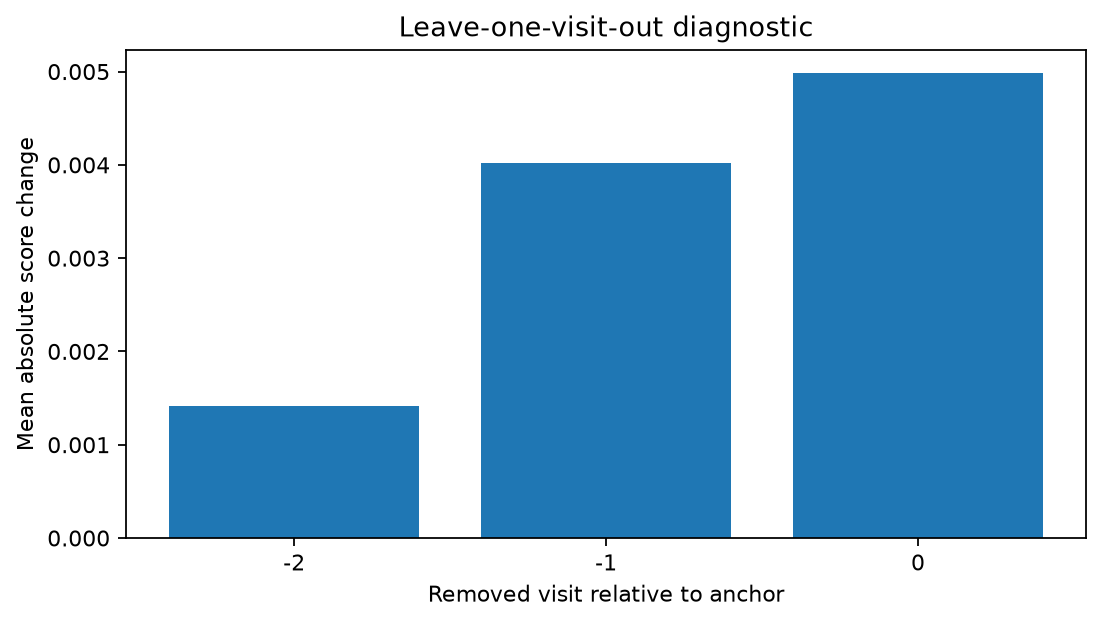

,relative_visit,n,mean_absolute_score_change
0,-2,8,0.00141
1,-1,12,0.00402
2,0,12,0.00499


**Missing MRI:** the table quantifies the fraction of visits with a fully missing MRI mask. These placeholders are not anatomical measurements. Visit ablation changes the model input distribution; changes in score are not evidence of causality.

In [10]:
show_figure('integrated_gradients.png')
display(pd.DataFrame(analysis['temporal_ig']).round(5))
display(Markdown(f"**Maximum absolute IG completeness residual:** {analysis['ig_max_abs_completeness_delta_logit']:.6f} logit units. This is not a clinical-validation score."))
show_figure('visit_ablation.png')
display(pd.DataFrame(analysis['visit_ablation']).round(5))
display(Markdown('**Missing MRI:** the table quantifies the fraction of visits with a fully missing MRI mask. These placeholders are not anatomical measurements. Visit ablation changes the model input distribution; changes in score are not evidence of causality.'))

## 8. Limitations and Conclusions

### What the experiment supports

The software pipeline can construct an auditable NACC74 cohort, enforce temporal availability, fit train-only transforms, train the specified MLP/GRU model, compare six prespecified arms, and reproduce frozen checkpoint inference. It does **not** establish clinical validity or diagnostic usefulness.

### Key limitations

- **Small sample:** 75 total participants; only 14 train, 3 validation and 3 test progressions. One additional detected test event changes sensitivity by 33 percentage points. The selected model has many trainable weights relative to 52 training patients and 149 correlated MRI variables.
- **Primary predictive failure:** train AUROC is much higher than validation AUROC; the test primary sensitivity is zero. A high majority-class accuracy is misleading here.
- **MRI missingness:** 106/209 selected visits lack quantitative MRI. All anchors have MRI, so history is predominantly clinical; availability may itself be associated with clinical workflows or selection. Placeholders must never be interpreted as anatomy.
- **Selection/follow-up bias:** MRI availability and complete outcome follow-up define a convenience cohort. Excluding insufficient follow-up is not a survival/censoring analysis. Results cannot be generalized to all MCI patients.
- **Mixed-protocol heterogeneity:** scanner/site/acquisition and MRI processing differences may confound signals. No external site validation, harmonization study or prospective deployment was performed.
- **Test already inspected:** the comparative test results are exploratory. No post-test change to threshold, model, split or feature count was made for this notebook. A new independent cohort is required for confirmatory comparison.
- **Baselines:** logistic vs GRU comparisons confound history with architecture. The primary and multimodal comparison are repeated configurations, not additional independent evidence.
- **Calibration and threshold:** probabilities from class-weighted training are not proven calibrated. Three validation positives cannot provide a stable operating threshold.
- **Explanation limits:** IG is conditional on fixed masks, absolute aggregation loses direction, correlated features can redistribute attribution, and zero baselines may be unrealistic. Visit occlusion can be out of distribution. Numerical completeness is not clinical faithfulness. No seed-stability assessment or external anatomical validation was completed.
- **Missing original artifacts:** epoch curves for unimodal GRUs and ROC/PR for logistic models are unavailable because histories/estimators/scores were not persisted. They are not fabricated or regenerated by retraining here.

### Conclusion

This delivery is a **research prototype with exploratory analysis**. The primary multimodal GRU misses all three observed test progressions at its fixed threshold. The clinical GRU has the highest observed comparative AUROC, but this is not evidence to declare it the final winner. Further work should be prospectively planned on development data, with stronger sample size and an untouched external/independent test cohort.

### References and Reproducibility

- NACC UDS Researcher's Data Dictionary, Version 4 (April 2026): https://files.alz.washington.edu/documentation/uds4-rdd.pdf
- NACC Mixed Protocol MRI Researcher's Data Dictionary (2026): https://files.alz.washington.edu/documentation/rdd-imaging-mri.pdf
- Public schema and missing codes: `configs/nacc_columns.json`, `configs/nacc74_mixed_protocol_mri.json`.
- Cohort/model logic: `source_pipeline.py`, `workstream1/pipeline.py`, `integration.py`, `model.py`, `training.py`, `evaluation.py`, `explainability.py` in `src/nacc_progression/`.
- Analysis figures: `artifacts/private_runs/freeze74/analysis_assets/`. All notebook/results folders remain Git-ignored. Keys and raw patient data are never embedded in notebook outputs.

**This notebook completes the analysis presentation, not clinical validation or the backend/frontend research interface.**

In [8]:
missing_total = sum(item['visits_without_quantitative_mri'] for item in counts['by_split'].values())
visit_total = counts['clinical_visits']
display(pd.DataFrame([{
    'total_participants': cohort['eligible_participants'],
    'selected_visits': visit_total,
    'visits_without_quantitative_MRI': missing_total,
    'fraction_without_MRI': missing_total / visit_total,
    'test_participants': counts['by_split']['test']['subjects'],
    'test_progressions': counts['split_label_counts']['test']['1'],
    'sensitivity_change_per_detected_test_event': 1 / counts['split_label_counts']['test']['1'],
}]).round(3))
display(Markdown('### Artifact completeness'))
display(pd.DataFrame({'Not recoverable without a new experiment': analysis['missing_artifacts']}))
assert results.loc['primary_multimodal', 'sensitivity'] == 0.0
assert results.loc['primary_multimodal', 'true_positives'] == 0
assert results.loc['primary_multimodal', 'false_negatives'] == 3
assert counts['retained_mri_features'] == 149
assert len(results) == 7
display(Markdown('**Validated:** eight requested sections, original frozen results, no re-training, no threshold tuning, no patient identifiers in displayed outputs. Comparative findings remain exploratory.'))

,total_participants,selected_visits,visits_without_quantitative_MRI,fraction_without_MRI,test_participants,test_progressions,sensitivity_change_per_detected_test_event
0,75,209,106,0.507,12,3,0.333


### Artifact completeness

,Not recoverable without a new experiment
0,Logistic estimators/scores were not persisted:...
1,Epoch histories of unimodal GRUs were not pers...
2,No seed-stability or external-validation exper...


**Validated:** eight requested sections, original frozen results, no re-training, no threshold tuning, no patient identifiers in displayed outputs. Comparative findings remain exploratory.